In [1]:
import os
import joblib
import pandas as pd
import shap
from dotenv import load_dotenv
from sqlalchemy import create_engine, URL

load_dotenv(".env", override=True)

url = URL.create(
    drivername="postgresql+psycopg2",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT")),
    database=os.getenv("DB_NAME"),
)
engine = create_engine(url)

df = pd.read_sql("SELECT * FROM patients", engine)
X = df.drop(columns=["target"])

saved = joblib.load("models/heart_disease_model.joblib")
model = saved["model"]
print("Loaded model, threshold =", saved["threshold"])

c:\Users\furqa\Documents\heart-disease-prediction\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded model, threshold = 0.35


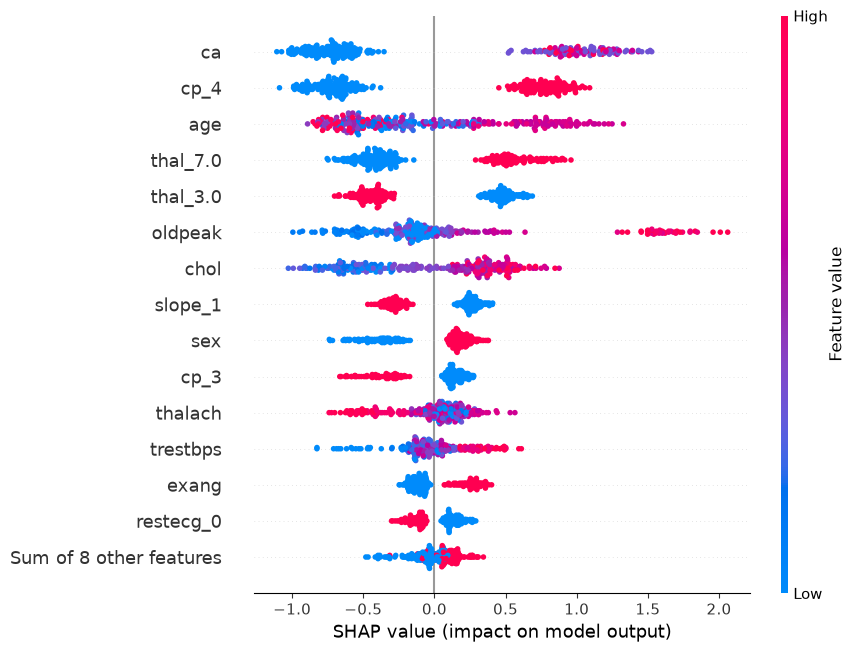

In [2]:
preprocess = model.named_steps["preprocess"]
xgb_model = model.named_steps["model"]

X_transformed = preprocess.transform(X)
feature_names = [name.split("__")[1] for name in preprocess.get_feature_names_out()]
X_transformed = pd.DataFrame(X_transformed, columns=feature_names)

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_transformed)

shap.plots.beeswarm(shap_values, max_display=15)

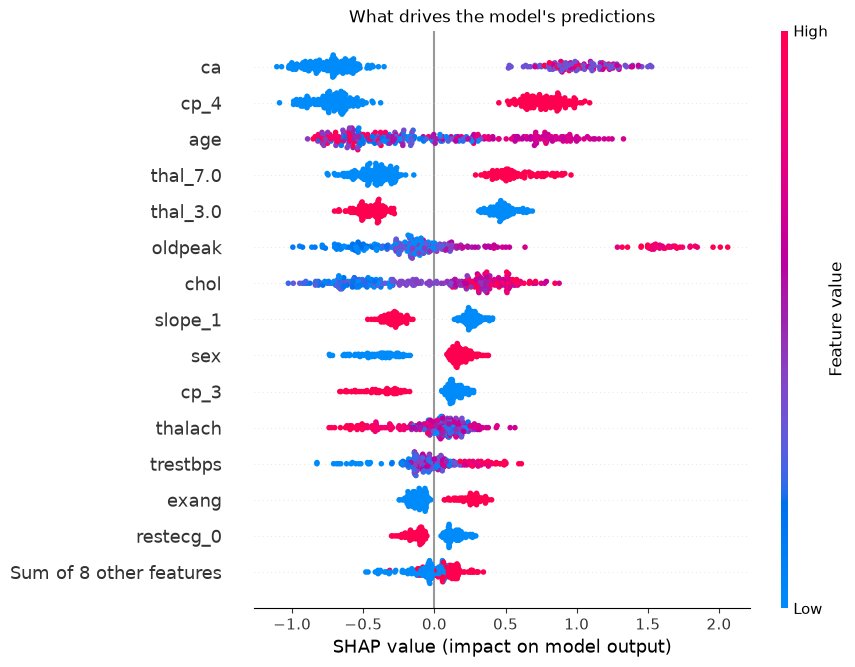

In [3]:
import matplotlib.pyplot as plt

shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("What drives the model's predictions")
plt.savefig("images/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

Predicted probability of disease: 97.7%
Actual diagnosis: Disease


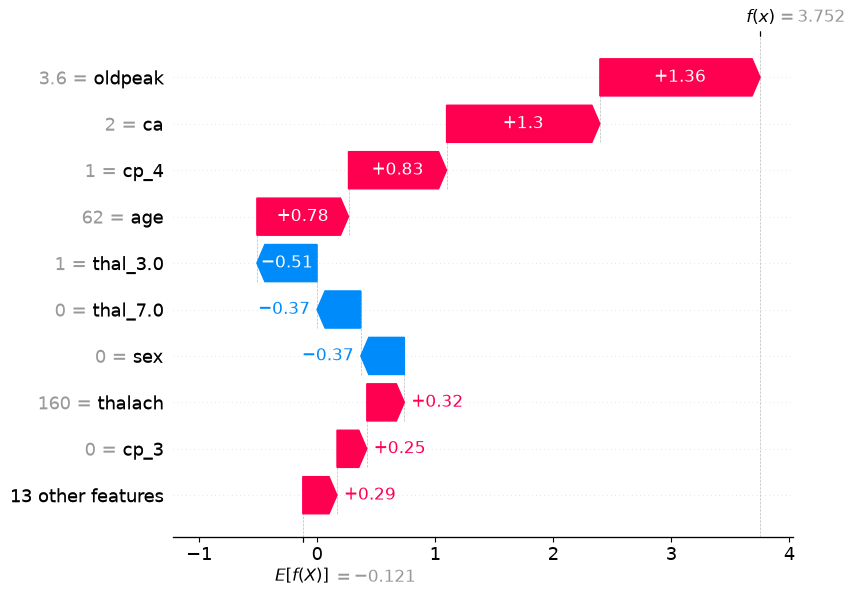

In [7]:
numeric_cols = ["age", "sex", "trestbps", "chol", "fbs", "thalach", "exang", "oldpeak", "ca"]

X_display = X_transformed.copy()
for col in numeric_cols:
    X_display[col] = X[col].values
shap_values.data = X_display.values

patient = 6

prob = model.predict_proba(X.iloc[[patient]])[:, 1][0]
print(f"Predicted probability of disease: {prob:.1%}")
print("Actual diagnosis:", "Disease" if df["target"].iloc[patient] == 1 else "No disease")

shap.plots.waterfall(shap_values[patient], max_display=10)

In [8]:
all_probs = model.predict_proba(X)[:, 1]
all_preds = (all_probs >= saved["threshold"]).astype(int)

missed = df.index[(all_preds == 0) & (df["target"] == 1)]
false_alarms = df.index[(all_preds == 1) & (df["target"] == 0)]

print("Missed sick patients:", list(missed))
print("False alarms:", list(false_alarms))

Missed sick patients: [144, 229, 242, 285]
False alarms: [33, 91, 101, 174, 181, 201, 249]


age          47.0
sex           1.0
cp            3.0
trestbps    108.0
chol        243.0
fbs           0.0
restecg       0.0
thalach     152.0
exang         0.0
oldpeak       0.0
slope         1.0
ca            0.0
thal          3.0
Name: 144, dtype: float64

Predicted probability of disease: 15.8%
Actual diagnosis: Disease


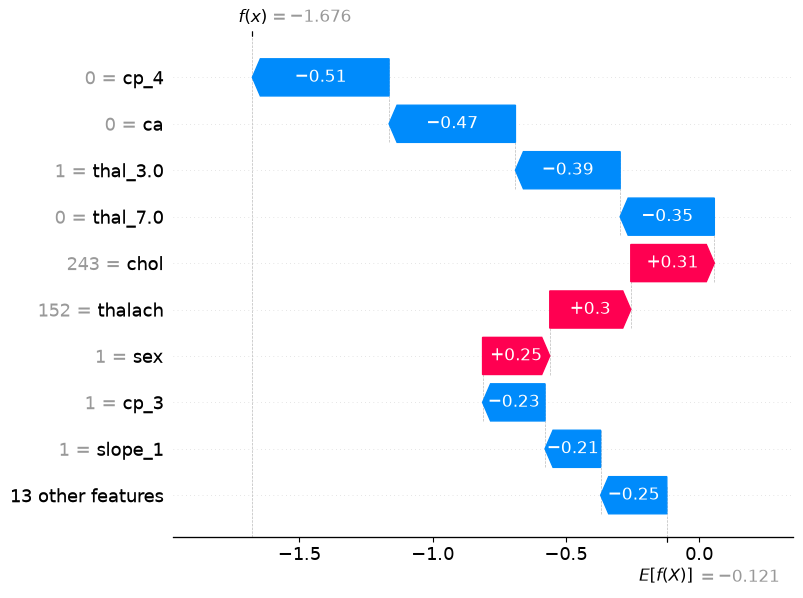

In [10]:
patient = 144

print(X.iloc[patient])

prob = model.predict_proba(X.iloc[[patient]])[:, 1][0]
print(f"\nPredicted probability of disease: {prob:.1%}")
print("Actual diagnosis:", "Disease" if df["target"].iloc[patient] == 1 else "No disease")

shap.plots.waterfall(shap_values[patient], max_display=10)

On every measurement the model trusts most, this man looks healthy. He's 47 with a clean stress test and clean imaging, yet he has disease. The waterfall shows it: his top four features all pushed risk down, and the few red pushes (male, cholesterol, heart rate) weren't nearly enough to counter them.

A cardiologist given only these 13 numbers would probably have struggled too. His disease was confirmed by a different, more invasive test (angiography) that isn't in the data. He may have milder disease that doesn't show up on a stress test.

The lesson: some errors are the model's fault, and some are the data's limit. You can often fix the first kind with better features or tuning. You can't fix the second kind, because the information simply isn't there. If we lowered the threshold enough to catch him, we'd also flag every healthy patient who looks just like him, which would be a huge number of false alarms.

This shapes the app. It needs a clear message such as: "A low score does not rule out heart disease. This tool supports clinical judgment and does not replace it." You now have real evidence for why that disclaimer is necessary, not just boilerplate.